# ClearBank — Análise Financeira com Python

Notebook do desafio final do módulo. Ele lê o histórico de transações exportado pela equipe de operações (`transacoes.csv`), descarta os registros com problema, calcula métricas financeiras por mês, sinaliza transações suspeitas, exibe um relatório formatado e salva o resultado em `relatorio.json`.

**Ordem do notebook:** arquivo de entrada → imports e constantes → leitura → validação → datas → métricas → JSON → relatório → **Célula de Execução Principal** → opcionais (pandas e gráfico).

Cada célula de código traz as funções da etapa e, no final, um bloco **Teste rápido** que confere se aquela parte funciona antes de seguir para a próxima.

### Instruções
1. Abra no Google Colab ou no Jupyter (Python 3.10+).
2. Execute as células **em ordem** (no Colab: *Ambiente de execução → Executar tudo*).
3. A primeira célula de código cria o `transacoes.csv`. Para usar outro arquivo, envie-o para a mesma pasta do notebook com esse nome e pule essa célula.
4. Saídas geradas: `relatorio.json` e, no opcional RO2, `grafico.png`.

## 0. Arquivo de entrada — `transacoes.csv`

O arquivo de teste tem **30 registros**: **20 válidos** distribuídos em 4 meses (jan–abr/2026) e **10 inválidos**, cobrindo todas as regras de validação:

| Registro | Problema esperado |
|---|---|
| id 4 | `valor` não numérico (`abc`) |
| id 7 | `cliente_id` vazio |
| sem id | `id` vazio |
| id 12 | data inexistente (`2026-02-30`) |
| id 15 | data fora do formato AAAA-MM-DD (`15/03/2026`) |
| id 17 | `tipo` inválido (`pix`) |
| id 19 | valor negativo |
| id 13 (2ª vez) | registro duplicado |
| `abc` | `id` não numérico |
| id 24 | valor igual a zero |

Há **3 transações acima de R$ 10.000,00** (ids 9, 16 e 22) e uma de **exatamente R$ 10.000,00** (id 27), que serve para testar a borda do limite — ela **não** deve ser sinalizada, pois a regra é "acima de".

In [1]:
%%writefile transacoes.csv
id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-18,CLI004,debito,1250.00,Aluguel,moradia
4,2026-01-20,CLI001,debito,abc,Erro de sistema,compra
5,2026-01-25,CLI003,credito,850.00,Freelance de design,servico
6,2026-01-28,CLI001,debito,89.90,Farmácia,saude
7,2026-02-03,,debito,200.00,Sem cliente,transferencia
8,2026-02-05,CLI001,credito,3500.00,Salário fevereiro,salario
,2026-02-10,CLI002,debito,75.00,Registro sem id,compra
9,2026-02-14,CLI003,credito,15000.00,Transferência recebida,transferencia
10,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
11,2026-02-22,CLI005,debito,640.75,Material de escritório,compra
12,2026-02-30,CLI004,debito,100.00,Data inexistente,compra
13,2026-03-01,CLI001,credito,3500.00,Salário março,salario
14,2026-03-10,CLI003,debito,99.90,Streaming,assinatura
15,15/03/2026,CLI003,credito,500.00,Data no formato errado,servico
16,2026-03-15,CLI004,debito,12500.00,Compra de veículo,compra
17,2026-03-18,CLI005,pix,300.00,Tipo inválido,transferencia
18,2026-03-21,CLI002,credito,2200.00,Reembolso,transferencia
19,2026-03-24,CLI002,debito,-50.00,Valor negativo,compra
20,2026-03-29,CLI005,debito,45.00,Estacionamento,transporte
13,2026-03-01,CLI001,credito,3500.00,Salário março,salario
21,2026-04-02,CLI001,credito,3500.00,Salário abril,salario
abc,2026-04-04,CLI003,debito,60.00,ID não numérico,compra
22,2026-04-08,CLI004,credito,22750.00,Venda de imóvel,transferencia
23,2026-04-15,CLI002,debito,410.30,Internet e telefone,conta
24,2026-04-18,CLI003,credito,0,Valor zerado,transferencia
25,2026-04-20,CLI003,debito,1500.00,Mensalidade da faculdade,educacao
26,2026-04-27,CLI005,debito,230.00,Restaurante,alimentacao
27,2026-04-30,CLI001,debito,10000.00,Transferência no limite,transferencia

Overwriting transacoes.csv


## 1. Imports e constantes

In [2]:
import csv
import io
import json
import math
from datetime import date, datetime

LIMITE_SUSPEITO = 10000.00        # transações ACIMA deste valor são suspeitas
ARQUIVO_CSV = "transacoes.csv"
ARQUIVO_JSON = "relatorio.json"
FORMATO_DATA = "%Y-%m-%d"
TIPOS_VALIDOS = ("credito", "debito")

print("Módulos importados: csv, io, json, math, datetime")
print(f"LIMITE_SUSPEITO = {LIMITE_SUSPEITO}")

Módulos importados: csv, io, json, math, datetime
LIMITE_SUSPEITO = 10000.0


## 2. Leitura do CSV com o módulo nativo `csv`

`csv.DictReader` entrega cada linha como dicionário, então as colunas são acessadas pelo nome. O `with open(...)` garante que o arquivo seja fechado, e o `try/except` evita que o programa pare se o arquivo não existir.

In [3]:
def ler_transacoes(caminho):
    """Lê o CSV e devolve a lista de linhas brutas (uma por transação).

    Se o arquivo não existir ou não estiver em UTF-8, avisa e devolve lista vazia.
    """
    try:
        # utf-8-sig também aceita arquivos salvos pelo Excel como "CSV UTF-8"
        with open(caminho, mode="r", encoding="utf-8-sig", newline="") as arquivo:
            return list(csv.DictReader(arquivo))
    except FileNotFoundError:
        print(f"[ERRO] Arquivo '{caminho}' não encontrado. Confira o nome e a pasta.")
    except UnicodeDecodeError:
        print(f"[ERRO] '{caminho}' não está em UTF-8. Salve-o como 'CSV UTF-8'.")
    return []


# ---------- Teste rápido ----------
linhas_teste = ler_transacoes(ARQUIVO_CSV)
print(f"Linhas lidas: {len(linhas_teste)}")
print(f"Colunas: {list(linhas_teste[0].keys())}")
print(f"Primeira linha: {linhas_teste[0]}")

print("\nTeste com arquivo inexistente:")
assert ler_transacoes("nao_existe.csv") == []
print("OK — o erro foi tratado e o programa continuou.")

Linhas lidas: 30
Colunas: ['id', 'data', 'cliente_id', 'tipo', 'valor', 'descricao', 'categoria']
Primeira linha: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}

Teste com arquivo inexistente:
[ERRO] Arquivo 'nao_existe.csv' não encontrado. Confira o nome e a pasta.
OK — o erro foi tratado e o programa continuou.


## 3. Validação e limpeza dos dados

Cada regra virou uma função pequena que **lança `ValueError` com o motivo** quando o dado é inválido. `limpar_transacoes()` percorre as linhas, captura o erro de cada uma, descarta a linha e continua — o programa nunca para por causa de um dado ruim.

| Campo | Regra |
|---|---|
| `id` | não pode ser vazio, deve ser numérico e não pode se repetir |
| `cliente_id` | não pode ser vazio |
| `data` | deve existir e estar exatamente em AAAA-MM-DD |
| `tipo` | `credito` ou `debito` |
| `valor` | numérico e maior que zero |

In [4]:
def obter_campo(linha, nome):
    """Devolve o campo sem espaços nas pontas ('' se estiver ausente)."""
    return (linha.get(nome) or "").strip()


def validar_id(texto):
    if not texto:
        raise ValueError("id vazio")
    if not texto.isdecimal():
        raise ValueError(f"id não numérico ({texto!r})")
    return int(texto)


def validar_data(texto):
    """Converte 'AAAA-MM-DD' em datetime; rejeita outros formatos e datas inexistentes."""
    try:
        data = datetime.strptime(texto, FORMATO_DATA)
    except ValueError:
        raise ValueError(f"data inválida ({texto!r})") from None
    # strptime aceita '2026-3-1'; convertendo de volta garantimos o formato exato
    if data.strftime(FORMATO_DATA) != texto:
        raise ValueError(f"data fora do formato AAAA-MM-DD ({texto!r})")
    return data


def validar_valor(texto):
    try:
        valor = float(texto)
    except ValueError:
        raise ValueError(f"valor não numérico ({texto!r})") from None
    if not math.isfinite(valor) or valor <= 0:
        raise ValueError(f"valor deve ser maior que zero ({texto!r})")
    return valor


def validar_transacao(linha):
    """Valida UMA linha do CSV e devolve o registro limpo (ou lança ValueError)."""
    id_transacao = validar_id(obter_campo(linha, "id"))
    cliente_id = obter_campo(linha, "cliente_id")
    if not cliente_id:
        raise ValueError("cliente_id vazio")
    data = validar_data(obter_campo(linha, "data"))
    tipo = obter_campo(linha, "tipo").lower()
    if tipo not in TIPOS_VALIDOS:
        raise ValueError(f"tipo inválido ({tipo!r})")
    return {
        "id": id_transacao,
        "data": data,
        "mes": data.strftime("%Y-%m"),
        "cliente_id": cliente_id,
        "tipo": tipo,
        "valor": validar_valor(obter_campo(linha, "valor")),
        "descricao": obter_campo(linha, "descricao"),
        "categoria": obter_campo(linha, "categoria"),
    }


def limpar_transacoes(linhas_brutas):
    """Separa linhas válidas e inválidas sem interromper o processamento."""
    validas, invalidas, ids_vistos = [], [], set()
    for numero_linha, linha in enumerate(linhas_brutas, start=2):  # linha 1 = cabeçalho
        try:
            registro = validar_transacao(linha)
            if registro["id"] in ids_vistos:
                raise ValueError(f"id {registro['id']} duplicado")
        except ValueError as erro:
            invalidas.append({"linha": numero_linha, "motivo": str(erro)})
            continue
        ids_vistos.add(registro["id"])
        validas.append(registro)
    return validas, invalidas


def exibir_resumo_limpeza(total_lidas, validas, invalidas):
    print("===== RESUMO DA LIMPEZA =====")
    print(f"Total de linhas lidas: {total_lidas}")
    print(f"Linhas válidas: {len(validas)}")
    print(f"Linhas inválidas: {len(invalidas)}")


# ---------- Teste rápido ----------
validas_teste, invalidas_teste = limpar_transacoes(linhas_teste)
exibir_resumo_limpeza(len(linhas_teste), validas_teste, invalidas_teste)

print("\nMotivos de descarte (linha do arquivo CSV):")
for item in invalidas_teste:
    print(f"  linha {item['linha']:>2}: {item['motivo']}")


def rejeita(funcao, texto):
    """True se a função de validação recusar o texto."""
    try:
        funcao(texto)
    except ValueError:
        return True
    return False


assert validar_valor("180.50") == 180.5 and validar_id("12") == 12
assert all(rejeita(validar_valor, v) for v in ["abc", "0", "-50", "", "nan"])
assert all(rejeita(validar_data, d) for d in ["15/03/2026", "2026-02-30", "2026-3-1", ""])
assert all(rejeita(validar_id, i) for i in ["", "abc", "1.5"])
print("\nTestes das funções de validação: OK")

===== RESUMO DA LIMPEZA =====
Total de linhas lidas: 30
Linhas válidas: 20
Linhas inválidas: 10

Motivos de descarte (linha do arquivo CSV):
  linha  5: valor não numérico ('abc')
  linha  8: cliente_id vazio
  linha 10: id vazio
  linha 14: data inválida ('2026-02-30')
  linha 17: data inválida ('15/03/2026')
  linha 19: tipo inválido ('pix')
  linha 21: valor deve ser maior que zero ('-50.00')
  linha 23: id 13 duplicado
  linha 25: id não numérico ('abc')
  linha 28: valor deve ser maior que zero ('0')

Testes das funções de validação: OK


## 4. Datas com `datetime`

A conversão com `strptime` já acontece na validação (`validar_data`), e o mês no formato AAAA-MM é extraído com `strftime("%Y-%m")`. Aqui calculamos o período coberto pelos dados e quantos dias se passaram entre a transação mais antiga e a mais recente.

In [5]:
def calcular_periodo(transacoes):
    """Devolve a data mais antiga, a mais recente e os dias entre elas."""
    if not transacoes:
        return None
    datas = [transacao["data"] for transacao in transacoes]
    inicio, fim = min(datas), max(datas)
    return {
        "inicio": inicio.strftime(FORMATO_DATA),
        "fim": fim.strftime(FORMATO_DATA),
        "dias": (fim - inicio).days,
    }


# ---------- Teste rápido ----------
exemplo = validas_teste[0]
print(f"Texto convertido: {type(exemplo['data']).__name__} -> {exemplo['data']}")
print(f"Mês extraído: {exemplo['mes']}")

periodo_teste = calcular_periodo(validas_teste)
print(f"Período: {periodo_teste['inicio']} → {periodo_teste['fim']} ({periodo_teste['dias']} dias)")
print(f"Meses nos dados: {sorted({t['mes'] for t in validas_teste})}")
assert calcular_periodo([]) is None

Texto convertido: datetime -> 2026-01-05 00:00:00
Mês extraído: 2026-01
Período: 2026-01-05 → 2026-04-30 (115 dias)
Meses nos dados: ['2026-01', '2026-02', '2026-03', '2026-04']


## 5. Agrupamento mensal, métricas e transações suspeitas

O agrupamento usa um dicionário com o mês como chave. Para cada mês são calculados: quantidade, total de crédito, total de débito, saldo, média por transação, maior e menor valor. Transações **acima** de `LIMITE_SUSPEITO` vão para uma lista separada.

O teste confere o resultado com o exemplo do enunciado (8 linhas → 6 válidas, 2 inválidas; janeiro com saldo de R$ 3.319,50 e média de R$ 1.840,25).

In [6]:
def agrupar_por_mes(transacoes):
    """Monta {'AAAA-MM': [transações do mês]} em ordem cronológica."""
    grupos = {}
    for transacao in sorted(transacoes, key=lambda t: t["data"]):
        grupos.setdefault(transacao["mes"], []).append(transacao)
    return grupos


def calcular_metricas_mes(transacoes_mes):
    total_credito = sum(t["valor"] for t in transacoes_mes if t["tipo"] == "credito")
    total_debito = sum(t["valor"] for t in transacoes_mes if t["tipo"] == "debito")
    maior = max(transacoes_mes, key=lambda t: t["valor"])
    menor = min(transacoes_mes, key=lambda t: t["valor"])
    quantidade = len(transacoes_mes)
    return {
        "quantidade": quantidade,
        "total_credito": round(total_credito, 2),
        "total_debito": round(total_debito, 2),
        "saldo": round(total_credito - total_debito, 2),
        "media": round((total_credito + total_debito) / quantidade, 2),
        "maior_valor": round(maior["valor"], 2),
        "id_maior_valor": maior["id"],
        "menor_valor": round(menor["valor"], 2),
        "id_menor_valor": menor["id"],
    }


def identificar_suspeitas(transacoes, limite=LIMITE_SUSPEITO):
    """Lista as transações com valor ACIMA do limite (o próprio limite não conta)."""
    suspeitas = []
    for t in transacoes:
        if t["valor"] > limite:
            suspeitas.append({
                "id": t["id"],
                "cliente_id": t["cliente_id"],
                "data": t["data"].strftime(FORMATO_DATA),
                "valor": round(t["valor"], 2),
            })
    return suspeitas


def gerar_relatorio(validas, invalidas):
    """Reúne métricas, período e suspeitas num dicionário pronto para exibir e salvar."""
    resumo_mensal = {}
    for mes, transacoes_mes in agrupar_por_mes(validas).items():
        resumo_mensal[mes] = calcular_metricas_mes(transacoes_mes)
    return {
        "gerado_em": date.today().isoformat(),
        "total_transacoes_validas": len(validas),
        "total_transacoes_invalidas": len(invalidas),
        "periodo": calcular_periodo(validas),
        "resumo_mensal": resumo_mensal,
        "limite_suspeito": LIMITE_SUSPEITO,
        "transacoes_suspeitas": identificar_suspeitas(validas),
    }


# ---------- Teste rápido ----------
# 1) Conferência com o exemplo do enunciado
EXEMPLO_ENUNCIADO = """id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-20,CLI001,debito,abc,Erro de sistema,compra
4,2026-02-03,,debito,200.00,Sem cliente,transferencia
5,2026-02-14,CLI003,credito,15000.00,Transferência suspeita,transferencia
6,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
7,2026-03-01,CLI001,credito,3500.00,Salário março,salario
8,2026-03-10,CLI003,debito,99.90,Streaming,assinatura"""

linhas_ex = list(csv.DictReader(io.StringIO(EXEMPLO_ENUNCIADO)))
validas_ex, invalidas_ex = limpar_transacoes(linhas_ex)
relatorio_ex = gerar_relatorio(validas_ex, invalidas_ex)
janeiro = relatorio_ex["resumo_mensal"]["2026-01"]
assert (len(linhas_ex), len(validas_ex), len(invalidas_ex)) == (8, 6, 2)
assert janeiro["quantidade"] == 2 and janeiro["total_credito"] == 3500.00
assert janeiro["total_debito"] == 180.50 and janeiro["saldo"] == 3319.50
assert janeiro["media"] == 1840.25
assert [s["id"] for s in relatorio_ex["transacoes_suspeitas"]] == [5]
print("Exemplo do enunciado: 8 lidas, 6 válidas, 2 inválidas, jan/2026 confere — OK")

# 2) Métricas dos nossos dados
relatorio_teste = gerar_relatorio(validas_teste, invalidas_teste)
print("\nMétricas por mês (transacoes.csv):")
for mes, m in relatorio_teste["resumo_mensal"].items():
    print(f"  {mes}: {m['quantidade']} transações | crédito {m['total_credito']:.2f}"
          f" | débito {m['total_debito']:.2f} | saldo {m['saldo']:.2f}")
print(f"\nSuspeitas (ids): {[s['id'] for s in relatorio_teste['transacoes_suspeitas']]}")

Exemplo do enunciado: 8 lidas, 6 válidas, 2 inválidas, jan/2026 confere — OK

Métricas por mês (transacoes.csv):
  2026-01: 5 transações | crédito 4350.00 | débito 1520.40 | saldo 2829.60
  2026-02: 4 transações | crédito 18500.00 | débito 960.75 | saldo 17539.25
  2026-03: 5 transações | crédito 5700.00 | débito 12644.90 | saldo -6944.90
  2026-04: 6 transações | crédito 26250.00 | débito 12140.30 | saldo 14109.70

Suspeitas (ids): [9, 16, 22]


## 6. Exportação do relatório em JSON

`json.dump` com `ensure_ascii=False` preserva os acentos e `indent=2` deixa o arquivo legível. As datas já estão como texto (AAAA-MM-DD), porque objetos `datetime` não são serializáveis em JSON.

In [7]:
def salvar_json(relatorio, caminho=ARQUIVO_JSON):
    """Grava o relatório em JSON. Devolve True se deu certo."""
    try:
        with open(caminho, mode="w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2)
    except OSError as erro:
        print(f"[ERRO] Não foi possível salvar '{caminho}': {erro}")
        return False
    print(f"Relatório salvo em '{caminho}'.")
    return True


# ---------- Teste rápido ----------
assert salvar_json(relatorio_teste)
with open(ARQUIVO_JSON, encoding="utf-8") as arquivo:
    relido = json.load(arquivo)
assert relido["total_transacoes_validas"] == len(validas_teste)
assert list(relido["resumo_mensal"]) == list(relatorio_teste["resumo_mensal"])
print("JSON relido e conferido. Início do arquivo:\n")
with open(ARQUIVO_JSON, encoding="utf-8") as arquivo:
    print("".join(arquivo.readlines()[:20]) + "  ...")

Relatório salvo em 'relatorio.json'.
JSON relido e conferido. Início do arquivo:

{
  "gerado_em": "2026-10-12",
  "total_transacoes_validas": 20,
  "total_transacoes_invalidas": 10,
  "periodo": {
    "inicio": "2026-01-05",
    "fim": "2026-04-30",
    "dias": 115
  },
  "resumo_mensal": {
    "2026-01": {
      "quantidade": 5,
      "total_credito": 4350.0,
      "total_debito": 1520.4,
      "saldo": 2829.6,
      "media": 1174.08,
      "maior_valor": 3500.0,
      "id_maior_valor": 1,
      "menor_valor": 89.9,
      "id_menor_valor": 6
  ...


## 7. Exibição formatada no terminal

Valores monetários no padrão brasileiro (`R$ 3.319,50`; saldo negativo como `-R$ 6.944,90`), separadores `=====` entre seções, período analisado e totais de válidas/inválidas.

In [8]:
def formatar_moeda(valor):
    """3319.5 -> 'R$ 3.319,50'   |   -6944.9 -> '-R$ 6.944,90'"""
    sinal = "-" if valor < 0 else ""
    texto = f"{abs(valor):,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{sinal}R$ {texto}"


def exibir_titulo(texto):
    print(f"\n===== {texto} =====")


def exibir_cabecalho(relatorio):
    exibir_titulo("RELATÓRIO CLEARBANK")
    periodo = relatorio["periodo"]
    print(f"Gerado em: {relatorio['gerado_em']}")
    print(f"Período analisado: {periodo['inicio']} → {periodo['fim']} ({periodo['dias']} dias)")
    print(f"Transações válidas: {relatorio['total_transacoes_validas']}")
    print(f"Transações inválidas: {relatorio['total_transacoes_invalidas']}")


def exibir_mes(mes, m):
    print(f"\nMês: {mes}")
    print(f"  Transações: {m['quantidade']}")
    print(f"  Total crédito: {formatar_moeda(m['total_credito'])}")
    print(f"  Total débito:  {formatar_moeda(m['total_debito'])}")
    print(f"  Saldo:         {formatar_moeda(m['saldo'])}")
    print(f"  Média:         {formatar_moeda(m['media'])}")
    print(f"  Maior valor:   {formatar_moeda(m['maior_valor'])} (ID {m['id_maior_valor']})")
    print(f"  Menor valor:   {formatar_moeda(m['menor_valor'])} (ID {m['id_menor_valor']})")


def exibir_suspeitas(suspeitas):
    exibir_titulo("TRANSAÇÕES SUSPEITAS")
    if not suspeitas:
        print("Nenhuma transação suspeita encontrada.")
        return
    for t in suspeitas:
        print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data']}"
              f" | Valor: {formatar_moeda(t['valor'])}")


def exibir_relatorio(relatorio):
    exibir_cabecalho(relatorio)
    exibir_titulo("RELATÓRIO MENSAL")
    for mes, metricas in relatorio["resumo_mensal"].items():
        exibir_mes(mes, metricas)
    exibir_suspeitas(relatorio["transacoes_suspeitas"])


# ---------- Teste rápido ----------
assert formatar_moeda(3319.5) == "R$ 3.319,50"
assert formatar_moeda(15000) == "R$ 15.000,00"
assert formatar_moeda(-6944.9) == "-R$ 6.944,90"
assert formatar_moeda(99.9) == "R$ 99,90"
print("formatar_moeda: OK")

print("\nCaso sem suspeitas:", end="")
exibir_suspeitas([])

formatar_moeda: OK

Caso sem suspeitas:
===== TRANSAÇÕES SUSPEITAS =====
Nenhuma transação suspeita encontrada.


## 8. Célula de Execução Principal

Roda o fluxo completo do zero: leitura → validação → métricas → relatório no terminal → `relatorio.json`.

In [9]:
def executar_analise(caminho_csv=ARQUIVO_CSV, caminho_json=ARQUIVO_JSON):
    """Executa a análise completa e devolve o relatório (ou None se não houver dados)."""
    linhas = ler_transacoes(caminho_csv)
    if not linhas:
        print("Nada para analisar: o arquivo está vazio ou não foi encontrado.")
        return None
    validas, invalidas = limpar_transacoes(linhas)
    exibir_resumo_limpeza(len(linhas), validas, invalidas)
    if not validas:
        print("Nenhuma transação válida para analisar.")
        return None
    relatorio = gerar_relatorio(validas, invalidas)
    exibir_relatorio(relatorio)
    print()
    salvar_json(relatorio, caminho_json)
    return relatorio


relatorio = executar_analise()

===== RESUMO DA LIMPEZA =====
Total de linhas lidas: 30
Linhas válidas: 20
Linhas inválidas: 10

===== RELATÓRIO CLEARBANK =====
Gerado em: 2026-10-12
Período analisado: 2026-01-05 → 2026-04-30 (115 dias)
Transações válidas: 20
Transações inválidas: 10

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações: 5
  Total crédito: R$ 4.350,00
  Total débito:  R$ 1.520,40
  Saldo:         R$ 2.829,60
  Média:         R$ 1.174,08
  Maior valor:   R$ 3.500,00 (ID 1)
  Menor valor:   R$ 89,90 (ID 6)

Mês: 2026-02
  Transações: 4
  Total crédito: R$ 18.500,00
  Total débito:  R$ 960,75
  Saldo:         R$ 17.539,25
  Média:         R$ 4.865,19
  Maior valor:   R$ 15.000,00 (ID 9)
  Menor valor:   R$ 320,00 (ID 10)

Mês: 2026-03
  Transações: 5
  Total crédito: R$ 5.700,00
  Total débito:  R$ 12.644,90
  Saldo:         -R$ 6.944,90
  Média:         R$ 3.668,98
  Maior valor:   R$ 12.500,00 (ID 16)
  Menor valor:   R$ 45,00 (ID 20)

Mês: 2026-04
  Transações: 6
  Total crédito: R$ 26.250,00
  To

## 9. Opcional RO1 — Análise com pandas

A versão com pandas fica no arquivo separado **`analise_pandas.py`** (o mesmo que está no repositório). A primeira célula abaixo grava o arquivo para que o notebook funcione sozinho no Colab; a segunda executa o script, que usa `pd.read_csv()`, aplica as mesmas regras de validação, agrupa por mês com `groupby` e compara os números com o `relatorio.json` da solução nativa.

In [10]:
%%writefile analise_pandas.py
"""ClearBank — versão alternativa da análise usando pandas (Requisito Opcional RO1).

Aplica as mesmas regras de validação da solução nativa, agrupa as transações
por mês com groupby e compara as métricas com o relatorio.json gerado pela
solução principal do notebook (os valores devem ser iguais).

Uso: rode o notebook primeiro (ele gera o relatorio.json) e depois
    python analise_pandas.py
"""
import json

import numpy as np
import pandas as pd

ARQUIVO_CSV = "transacoes.csv"
ARQUIVO_JSON = "relatorio.json"
TIPOS_VALIDOS = ["credito", "debito"]
METRICAS = ["quantidade", "total_credito", "total_debito", "saldo",
            "media", "maior_valor", "menor_valor"]
TOLERANCIA = 0.005  # diferença máxima aceita (meio centavo)


def carregar_dados(caminho=ARQUIVO_CSV):
    """Lê o CSV com pd.read_csv mantendo tudo como texto (vazio continua vazio)."""
    df = pd.read_csv(caminho, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    return df.apply(lambda coluna: coluna.str.strip())


def limpar_dados(df):
    """Aplica as regras da solução nativa. Devolve (validas, quantidade_invalidas)."""
    datas = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")
    valores = pd.to_numeric(df["valor"], errors="coerce")
    tipos = df["tipo"].str.lower()
    linha_valida = (
        df["id"].str.fullmatch(r"\d+")
        & (df["cliente_id"] != "")
        & (datas.dt.strftime("%Y-%m-%d") == df["data"])   # formato exato AAAA-MM-DD
        & tipos.isin(TIPOS_VALIDOS)
        & np.isfinite(valores)
        & (valores > 0)
    )
    df = df.assign(id=pd.to_numeric(df["id"], errors="coerce"),
                   data=datas, tipo=tipos, valor=valores)
    validas = df[linha_valida]
    validas = validas[~validas["id"].duplicated(keep="first")]  # id repetido = inválido
    return validas, len(df) - len(validas)


def resumo_mensal_pandas(validas):
    """Agrupa por mês (AAAA-MM) com groupby e calcula as mesmas métricas da versão nativa."""
    df = validas.assign(
        mes=validas["data"].dt.strftime("%Y-%m"),
        credito=validas["valor"].where(validas["tipo"] == "credito", 0.0),
        debito=validas["valor"].where(validas["tipo"] == "debito", 0.0),
    )
    resumo = df.groupby("mes").agg(
        quantidade=("valor", "size"),
        total_credito=("credito", "sum"),
        total_debito=("debito", "sum"),
        media=("valor", "mean"),
        maior_valor=("valor", "max"),
        menor_valor=("valor", "min"),
    )
    resumo["saldo"] = resumo["total_credito"] - resumo["total_debito"]
    return resumo[METRICAS].round(2)


def carregar_resumo_nativo(caminho=ARQUIVO_JSON):
    """Lê o relatorio.json da solução nativa e devolve (dados, resumo em DataFrame)."""
    with open(caminho, encoding="utf-8") as arquivo:
        nativo = json.load(arquivo)
    resumo = pd.DataFrame(nativo["resumo_mensal"]).T[METRICAS].astype(float)
    resumo.index.name = "mes"
    return nativo, resumo


def comparar_com_nativo(resumo_pd, validas, invalidas):
    """Compara contagens e métricas mês a mês. Devolve True se forem iguais."""
    try:
        nativo, resumo_nat = carregar_resumo_nativo()
    except FileNotFoundError:
        print(f"'{ARQUIVO_JSON}' não encontrado — execute a solução nativa antes.")
        return False
    print("\n===== COMPARAÇÃO COM A SOLUÇÃO NATIVA =====")
    print(f"Válidas:   pandas {len(validas):>3} | nativo {nativo['total_transacoes_validas']:>3}")
    print(f"Inválidas: pandas {invalidas:>3} | nativo {nativo['total_transacoes_invalidas']:>3}")
    mesmos_meses = list(resumo_pd.index) == list(resumo_nat.index)
    print(f"Meses: {', '.join(resumo_pd.index)} | iguais: {'sim' if mesmos_meses else 'NÃO'}")
    if not mesmos_meses:
        return False
    diferenca = (resumo_pd.astype(float) - resumo_nat).abs().to_numpy().max()
    print(f"Maior diferença entre as métricas: {diferenca:.4f}")
    return (len(validas) == nativo["total_transacoes_validas"]
            and invalidas == nativo["total_transacoes_invalidas"]
            and diferenca < TOLERANCIA)


def exibir_tabela(resumo):
    """Mostra o resumo mensal com valores no padrão brasileiro."""
    def moeda(valor):
        return f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    formatos = {coluna: moeda for coluna in METRICAS if coluna != "quantidade"}
    print("\n===== RESUMO MENSAL (pandas) =====")
    print(resumo.to_string(formatters=formatos))


def main():
    try:
        df = carregar_dados()
    except FileNotFoundError:
        print(f"Arquivo '{ARQUIVO_CSV}' não encontrado.")
        return
    validas, invalidas = limpar_dados(df)
    print("===== LIMPEZA (pandas) =====")
    print(f"Total de linhas lidas: {len(df)}")
    print(f"Linhas válidas: {len(validas)}")
    print(f"Linhas inválidas: {invalidas}")
    resumo = resumo_mensal_pandas(validas)
    exibir_tabela(resumo)
    if comparar_com_nativo(resumo, validas, invalidas):
        print("✔ Os resultados do pandas são iguais aos da solução nativa.")
    else:
        print("✘ Há diferenças entre pandas e a solução nativa — verifique as regras.")


if __name__ == "__main__":
    main()

Overwriting analise_pandas.py


In [11]:
%run analise_pandas.py

===== LIMPEZA (pandas) =====
Total de linhas lidas: 30
Linhas válidas: 20
Linhas inválidas: 10

===== RESUMO MENSAL (pandas) =====
         quantidade total_credito total_debito     saldo    media maior_valor menor_valor
mes                                                                                      
2026-01           5      4.350,00     1.520,40  2.829,60 1.174,08    3.500,00       89,90
2026-02           4     18.500,00       960,75 17.539,25 4.865,19   15.000,00      320,00
2026-03           5      5.700,00    12.644,90 -6.944,90 3.668,98   12.500,00       45,00
2026-04           6     26.250,00    12.140,30 14.109,70 6.398,38   22.750,00      230,00

===== COMPARAÇÃO COM A SOLUÇÃO NATIVA =====
Válidas:   pandas  20 | nativo  20
Inválidas: pandas  10 | nativo  10
Meses: 2026-01, 2026-02, 2026-03, 2026-04 | iguais: sim
Maior diferença entre as métricas: 0.0000
✔ Os resultados do pandas são iguais aos da solução nativa.


## 10. Opcional RO2 — Gráfico com matplotlib

**Opção A:** barras com o saldo mensal (crédito − débito). Azul indica saldo positivo e vermelho, negativo; cada barra traz o valor escrito, então a leitura não depende só da cor. O gráfico é salvo como `grafico.png`.

Gráfico salvo em 'grafico.png'.


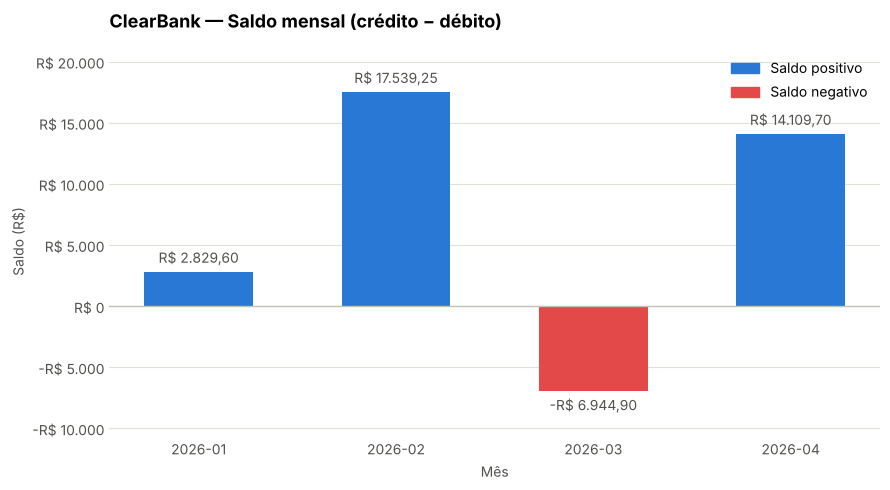

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

COR_POSITIVO = "#2a78d6"   # azul — saldo positivo
COR_NEGATIVO = "#e34948"   # vermelho — saldo negativo
COR_TEXTO, COR_EIXO, COR_GRADE = "#52514e", "#c3c2b7", "#e1e0d9"


def rotulo_eixo(valor, _posicao=None):
    """Valores do eixo Y sem centavos: 15000 -> 'R$ 15.000'."""
    return formatar_moeda(valor)[:-3]


def estilizar_eixos(ax):
    for lado in ("top", "right", "left", "bottom"):
        ax.spines[lado].set_visible(False)   # a linha do zero já serve de base
    ax.grid(axis="y", color=COR_GRADE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=COR_TEXTO, length=0)
    ax.yaxis.set_major_formatter(rotulo_eixo)


def gerar_grafico(relatorio, caminho="grafico.png"):
    """Opção A: gráfico de barras com o saldo mensal, salvo em PNG."""
    meses = list(relatorio["resumo_mensal"])
    saldos = [relatorio["resumo_mensal"][mes]["saldo"] for mes in meses]
    cores = [COR_POSITIVO if saldo >= 0 else COR_NEGATIVO for saldo in saldos]

    fig, ax = plt.subplots(figsize=(9, 5))
    barras = ax.bar(meses, saldos, color=cores, width=0.55)
    ax.bar_label(barras, labels=[formatar_moeda(s) for s in saldos],
                 padding=4, fontsize=10, color=COR_TEXTO)
    ax.axhline(0, color=COR_EIXO, linewidth=1)
    ax.margins(y=0.15)
    estilizar_eixos(ax)
    ax.set_title("ClearBank — Saldo mensal (crédito − débito)", loc="left",
                 fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel("Mês", color=COR_TEXTO)
    ax.set_ylabel("Saldo (R$)", color=COR_TEXTO)
    ax.legend(handles=[Patch(color=COR_POSITIVO, label="Saldo positivo"),
                       Patch(color=COR_NEGATIVO, label="Saldo negativo")],
              frameon=False, loc="upper right")
    fig.tight_layout()
    fig.savefig(caminho, dpi=150)
    print(f"Gráfico salvo em '{caminho}'.")
    plt.show()


gerar_grafico(relatorio)